# SML processing example

This is a simple example of using the SML attenuation data for rainfall estimation. 

The notebook is currently WIP...

In [1]:
import xarray as xr
import matplotlib.pyplot as plt

## Load and plot example data from the OpenSat4Weather dataset

This is a short period of the OpenSat4Weather dataset (https://doi.org/10.5194/essd-2025-537) used for demonstration purposes.

In [2]:
ds_smls = xr.open_dataset('../misc/example_data/opensat4weather_example_sml.nc')
ds_radar_along_smls = xr.open_dataset('../misc/example_data/opensat4weather_example_radar.nc')

In [3]:
ds_smls

<xarray.Dataset> Size: 84MB
Dimensions:              (sml_id: 215, time: 24480)
Coordinates:
  * sml_id               (sml_id) <U9 8kB 'FRA-00002' ... 'FRA-00737'
  * time                 (time) datetime64[ns] 196kB 2022-08-09 ... 2022-08-2...
    site_0_lat           (sml_id) float64 2kB ...
    site_0_lon           (sml_id) float64 2kB ...
    site_0_alt           (sml_id) int64 2kB ...
    satellite_azimuth    (sml_id) float64 2kB ...
    satellite_elevation  (sml_id) float64 2kB ...
    satellite            (sml_id) <U11 9kB ...
    hardware             (sml_id) <U4 3kB ...
Data variables:
    rsl                  (sml_id, time) float64 42MB ...
    deg0l                (sml_id, time) float64 42MB ...
Attributes:
    creation_date:  2025-07-28
    title:          Satellite Microwave Link dataset Aug-Dec 2022
    version:        1.0
    convention:     OpenSense-1.0
    reference:      rsl data from HDrain, deg0l data from ERA5 (https://clima...
    authors:        Roberto Nebuloni, Maximilian Graf, Greta Cazzaniga, Franc...

Text(0.5, 0, 'time')

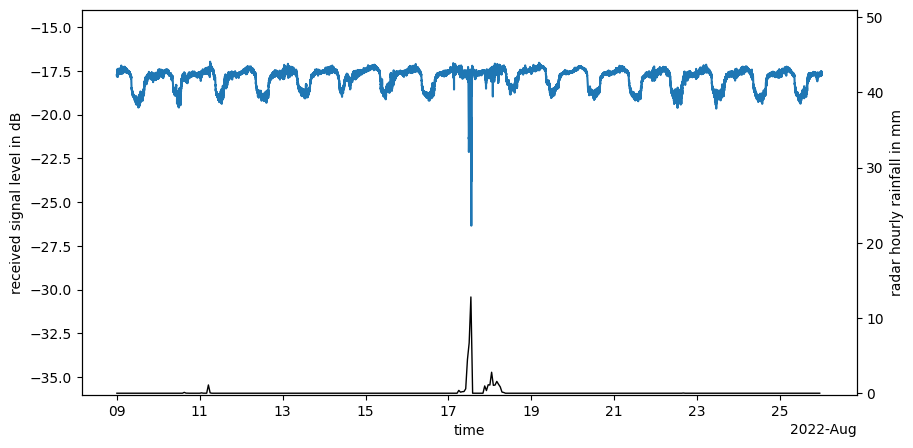

In [4]:
sml_id = 'FRA-00022'

fig, ax = plt.subplots(figsize=(10, 5))
ds_smls.rsl.sel(sml_id=sml_id).plot()
ax.set_ylim(-36, -14)
ax.set_ylabel("received signal level in dB")

ax2 = ax.twinx()
ds_radar_along_smls.rainfall_amount.sel(sml_id=sml_id).resample(time='1h').sum().plot(
    ax=ax2, color='k', zorder=-1, linewidth=1,
)
ax2.set_ylim(-0.2, 51)
ax2.set_ylabel("radar hourly rainfall in mm")
ax.set_title('')
ax2.set_title('')
ax.set_xlabel("time")


## Use Kalman filters for wet-dry classification

This follows the approach described by https://doi.org/10.1109/SSP.2018.8450692 based on code from the OpenSense training school https://github.com/OpenSenseAction/training_school_opensene_2023.

In [5]:
# The following functions were derived from the Kalman filter code from https://github.com/OpenSenseAction/training_school_opensene_2023

import numpy as np


def _kalman_filter(observations, Q, R):
    """Run a standard 1D Kalman filter on the given observations.

    NaN values in the observations are skipped: the state is carried
    forward unchanged for those time steps.

    Parameters
    ----------
    observations : array-like
        The measured signal to be filtered.
    Q : float
        Process variance.
    R : float
        Measurement variance.

    Returns
    -------
    xhat : np.ndarray
        The a posteriori state estimate (filtered signal).
    """
    z = np.asarray(observations, dtype=float)
    n_iter = len(z)
    sz = (n_iter,)  # size of array

    # allocate space for arrays
    xhat = np.zeros(sz)  # a posteri estimate of x
    P = np.zeros(sz)  # a posteri error estimate
    xhatminus = np.zeros(sz)  # a priori estimate of x
    Pminus = np.zeros(sz)  # a priori error estimate
    K = np.zeros(sz)  # gain or blending factor

    # intial guesses
    xhat[0] = np.nanmedian(z)
    P[0] = 1.0

    for k in range(1, n_iter):
        # time update
        xhatminus[k] = xhat[k - 1]
        Pminus[k] = P[k - 1] + Q

        # measurement update (skip NaN observations)
        if np.isnan(z[k]):
            xhat[k] = xhatminus[k]
            P[k] = Pminus[k]
            continue

        K[k] = Pminus[k] / (Pminus[k] + R)
        xhat[k] = xhatminus[k] + K[k] * (z[k] - xhatminus[k])
        P[k] = (1 - K[k]) * Pminus[k]
    return xhat


def Kalman_ST(rsl, Q=10e-5):
    R = 1  # estimate of measurement variance
    Q = 1e-3 # process variance
    return _kalman_filter(rsl, Q=Q, R=R)


def Kalman_FT(rsl):
    R = 1# estimate of measurement variance, change to see effect
    Q = 1e-1  # process variance
    return _kalman_filter(rsl, Q=Q, R=R)

(np.float64(19219.0), np.float64(19224.999305555557))

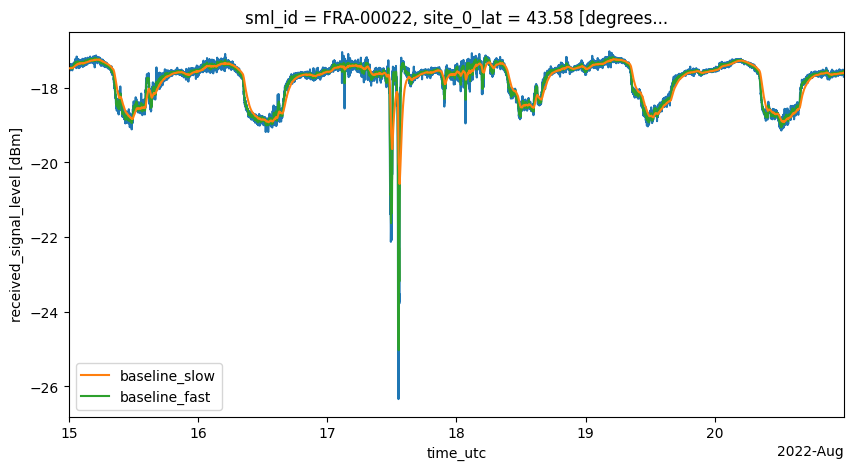

In [6]:
sml_id = 'FRA-00022'

baseline_slow = Kalman_ST(ds_smls.rsl.sel(sml_id=sml_id).data)
baseline_fast = Kalman_FT(ds_smls.rsl.sel(sml_id=sml_id).data)

ds_smls.rsl.sel(sml_id=sml_id).plot(figsize=(10, 5))
plt.plot(ds_smls.sel(sml_id=sml_id).time, baseline_slow, label='baseline_slow', zorder=5)
plt.plot(ds_smls.sel(sml_id=sml_id).time, baseline_fast, label='baseline_fast')
plt.legend()
plt.xlim(ds_smls.time.sel(time=slice('2022-08-15', '2022-08-20')).min(), ds_smls.time.sel(time=slice('2022-08-15', '2022-08-20')).max())

### ...WIP... wet-dry

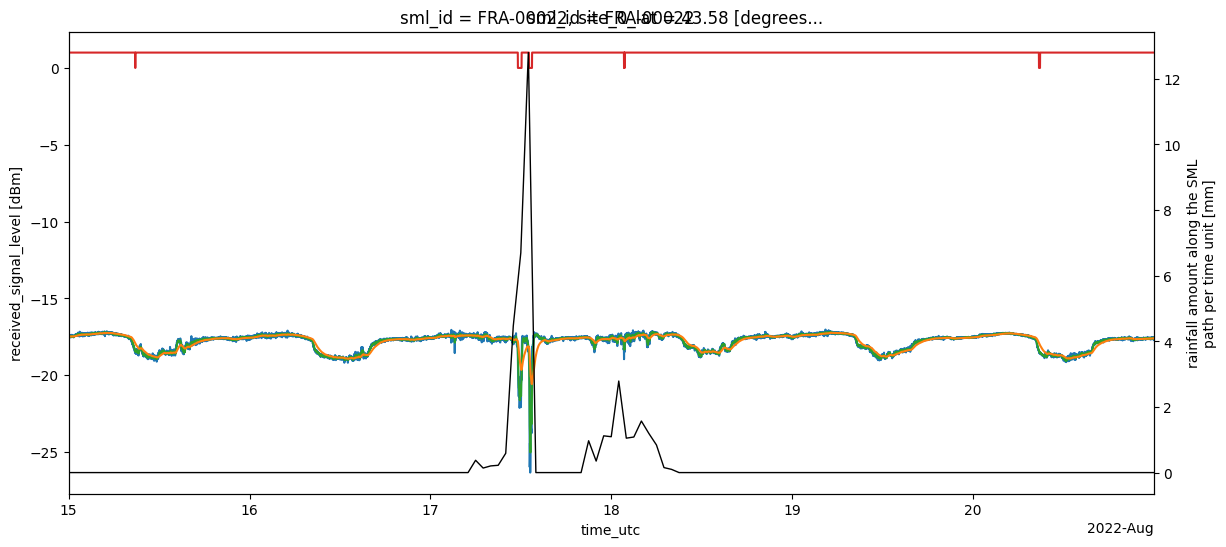

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
ds_smls.rsl.sel(sml_id=sml_id).plot(ax=ax)
plt.plot(ds_smls.sel(sml_id=sml_id).time, baseline_slow, label='baseline_slow', zorder=5)
plt.plot(ds_smls.sel(sml_id=sml_id).time, baseline_fast, label='baseline_fast')
plt.plot(ds_smls.sel(sml_id=sml_id).time, (baseline_slow - 0.5) < baseline_fast, label='baseline_slow', zorder=5)
plt.xlim(ds_smls.time.sel(time=slice('2022-08-15', '2022-08-20')).min(), ds_smls.time.sel(time=slice('2022-08-15', '2022-08-20')).max())

ax2 = ax.twinx()
ds_radar_along_smls.rainfall_amount.sel(sml_id=sml_id).resample(time='1h').sum().plot(
    ax=ax2, color='k', zorder=-1, linewidth=1,
)


## Calculate rain rate... WIP